## Task 1 - Data Loading, EDA & Preprocessing

### 1.1 - Load the dataset

In [51]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow import keras

from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("X.shape:" , X.shape)

print("y.value_counts():" , y.value_counts())

X.shape: (569, 30)
y.value_counts(): target
1    357
0    212
Name: count, dtype: int64


In [3]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### 1.2 - Class distribution plot

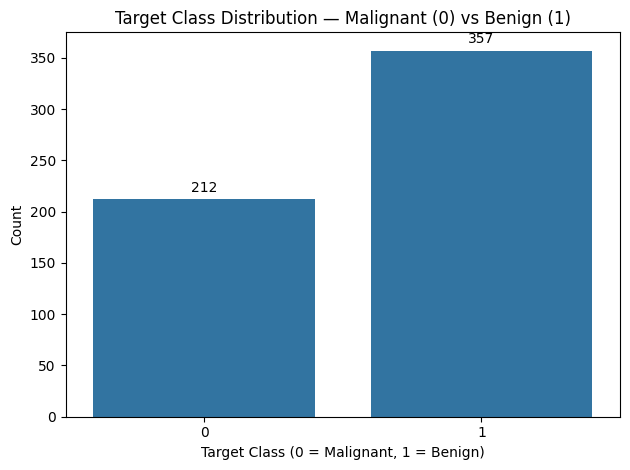

In [4]:
ax = sns.countplot(x=y)

ax.set_title('Target Class Distribution — Malignant (0) vs Benign (1)')
ax.set_xlabel('Target Class (0 = Malignant, 1 = Benign)')
ax.set_ylabel('Count')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

### Class Imbalance and Its Implications

The breast cancer dataset contains 569 samples: 212 malignant cases (class 0, approximately 37.3%) and 357 benign cases (class 1, approximately 62.7%). This represents a mild class imbalance.

For a binary classification task of this size, special handling such as oversampling or undersampling is not necessarily required. A reasonable starting point is to use a stratified train-test split and evaluate the model using metrics beyond accuracy, including precision, recall, F1-score, and the confusion matrix.

Because missing malignant cases can have serious consequences, particular attention should be paid to malignant-class recall (sensitivity). If model evaluation reveals poor minority-class performance, techniques such as class weighting or carefully applied resampling can be considered. Any resampling should be performed only on the training data to avoid data leakage.

### 1.3 - Feature correlation heatmap

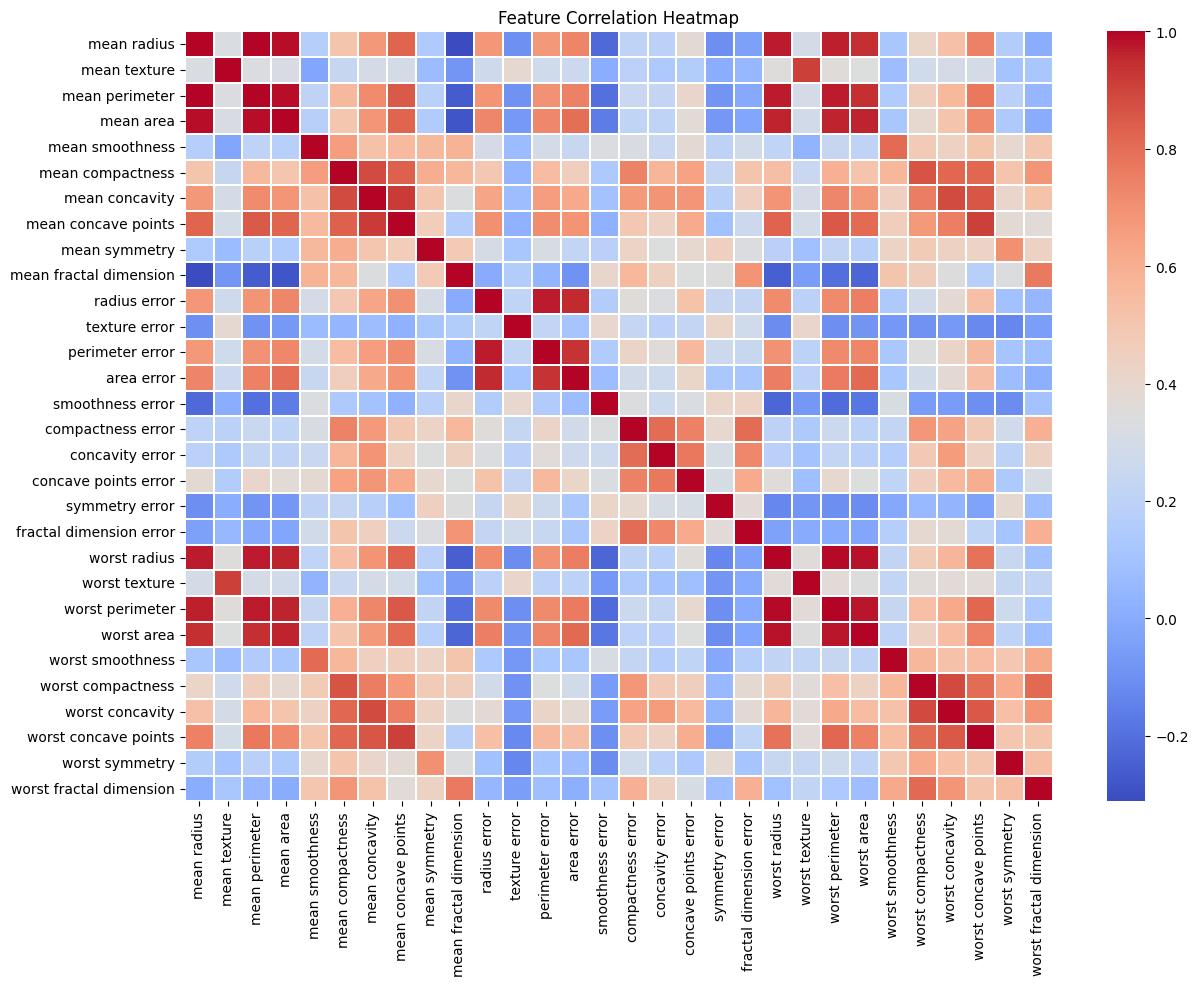

In [5]:
corr = X.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr,annot=False,cmap='coolwarm',linewidths=0.3)

plt.title('Feature Correlation Heatmap')
plt.show()

### Observation: Feature Correlation

The correlation heatmap shows that several features in the breast cancer dataset are highly correlated.

Examples of highly correlated feature pairs:

1. radius_mean and perimeter_mean — larger radii generally correspond to larger perimeters.
2. radius_mean and area_mean — larger-radius tumors generally have larger areas.
3. perimeter_mean and area_mean — perimeter and area tend to increase together.

Does high inter-feature correlation cause a problem for neural networks?

High inter-feature correlation is generally less problematic for neural networks than for linear models.

- Linear models: Highly correlated features can cause multicollinearity, making coefficient estimates unstable and harder to interpret.

- Neural networks: Neural networks can learn nonlinear relationships and distribute information across multiple features. Correlated inputs do not automatically make training unstable or invalidate the model.

### 1.4 - Train / test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


In [7]:
print("Training set class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting set class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training set class proportions:
target
0    0.374
1    0.626
Name: proportion, dtype: float64

Testing set class proportions:
target
0    0.368
1    0.632
Name: proportion, dtype: float64


### 1.5 - Apply StandardScaler

In [8]:
scaler = StandardScaler()

scaler.fit(X_train)

X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

print("Training feature means:")
print(X_train_sc.mean(axis=0).round(2))

print("\nTraining feature standard deviations:")
print(X_train_sc.std(axis=0).round(2))

Training feature means:
[-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


### Observation: Feature Scaling

We used StandardScaler to standardize the features so that they have approximately zero mean and unit standard deviation.

Why do we fit the scaler only on the training data ?

- Avoid data leakage: Fitting the scaler on the test data would allow information from the test set to influence preprocessing.

- Fair evaluation: The test set should represent unseen data. Its statistics must not influence the training process.

- Consistent transformation: We use the means and standard deviations learned from X_train to transform both X_train and X_test.

The training data has means close to 0 and standard deviations close to 1 after scaling. The test data may not have exactly these values because it uses the training set's scaling parameters.

This scaling is especially useful for neural networks because it can improve optimization and help training converge more efficiently.

### 1.6 - WHY scaling for neural networks

### Why Feature Scaling Is Important for Neural Networks

Gradient-based optimizers, such as SGD and Adam, generally converge faster and more stably when input features are on similar scales.

- Without scaling: Features with large numerical ranges, such as area_mean (which can reach around 2500), may have a disproportionately large influence on early gradient updates. Meanwhile, small-range features, such as fractal_dimension_mean (often around 0.05–0.10), may have less influence due to their numerical scale.

- The problem: Different feature scales can lead to inefficient optimization, slower convergence, and difficulty finding suitable model weights.

- With StandardScaler: Each feature is transformed to have approximately zero mean and unit standard deviation, reducing differences in numerical scale.

Therefore, standardization helps neural networks learn more efficiently and can improve training stability. It does not guarantee better performance, but it provides a good starting point for training.


## Task 2: Single-Layer Perceptron (SLP) - Baseline Model

### 2.1 - Build the SLP

In [9]:
model_slp = keras.Sequential([
    keras.layers.Dense(1,activation='sigmoid',input_shape=(30,))
])

model_slp.summary()

c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

### 2.2 - Compile the SLP

In [10]:
model_slp.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### Why Use Binary Cross-Entropy Loss?

Binary cross-entropy is the appropriate loss function for binary classification because it measures how well the model's predicted probabilities match the true labels (0 or 1).

- Log-likelihood: It is based on the likelihood of the observed labels given the predicted probabilities. Correct, confident predictions receive a low loss, while incorrect, confident predictions receive a high loss.

- Works with sigmoid: Our SLP uses a sigmoid activation function to predict a probability between 0 and 1, making binary cross-entropy a natural choice.

- Why not MSE ? : Mean squared error (MSE) is commonly used for regression, where the goal is to predict continuous numerical values. Although MSE can be used for classification, binary cross-entropy is generally better suited to learning probabilities for binary classification.

Therefore, we use binary_crossentropy to train our SLP to distinguish between malignant (0) and benign (1) cases.


### 2.3 - Train the SLP

In [11]:
history_slp = model_slp.fit(X_train_sc,y_train,epochs=50,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.5086 - loss: 0.7733 - val_accuracy: 0.3043 - val_loss: 0.9254
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6039 - loss: 0.6974 - val_accuracy: 0.3913 - val_loss: 0.8479
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6699 - loss: 0.6324 - val_accuracy: 0.5000 - val_loss: 0.7789
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7237 - loss: 0.5766 - val_accuracy: 0.6087 - val_loss: 0.7186
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7653 - loss: 0.5291 - val_accuracy: 0.6304 - val_loss: 0.6671
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8020 - loss: 0.4889 - val_accuracy: 0.6304 - val_loss: 0.6234
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8460 - loss: 0.4539 - val_accuracy: 0.6957 - val_loss: 0.5846
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8680 - loss: 0.4247 - val_accuracy: 0.7174 - val_los

### 2.4 - Plot SLP training curves

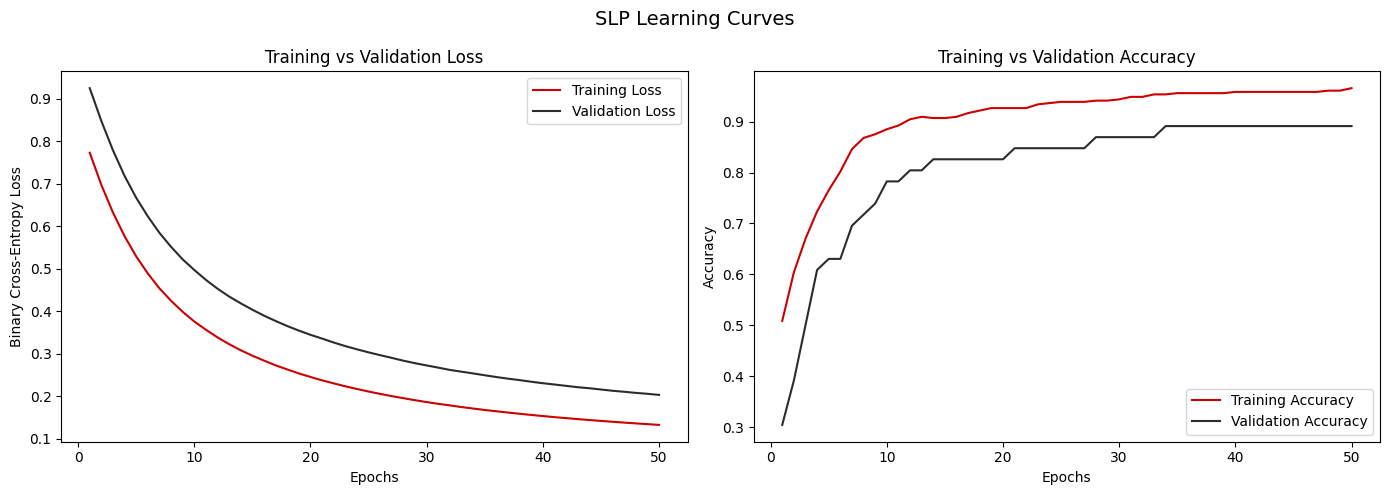

In [12]:
history = history_slp.history
epochs = range(1, len(history['loss']) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history['loss'], color='#CC0000', label='Training Loss')
plt.plot(epochs, history['val_loss'], color='#2C2C2C', label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history['accuracy'], color='#CC0000', label='Training Accuracy')
plt.plot(epochs, history['val_accuracy'], color='#2C2C2C', label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.suptitle('SLP Learning Curves', fontsize=14)
plt.tight_layout()
plt.show()

### Observation: SLP Learning Curves

The learning curves show that the Single-Layer Perceptron (SLP) learns effectively over 50 epochs.

- Convergence: Training loss decreases smoothly from approximately 1.07 to 0.13, while training accuracy increases from about 31% to 97%. This indicates that the model is learning and gradually converging.

- Training V/S validation loss: Both losses decrease steadily. Validation loss ends at approximately 0.16, slightly higher than training loss. This small gap suggests reasonable generalization with no clear sign of severe overfitting.

- Training V/S validation accuracy: Validation accuracy rises quickly and stabilizes around 96%, while training accuracy reaches approximately 97%. The small gap indicates that the model performs similarly on both datasets.

Conclusion: The SLP converges smoothly and shows a small gap between training and validation performance. It appears to generalize well to the validation data, although its final performance should be confirmed using the separate test set. Since this model has no hidden layers, it provides a useful baseline for comparison with more complex neural networks.


### 2.5 - Evaluate the SLP

In [13]:
slp_loss, slp_acc = model_slp.evaluate(X_test_sc, y_test, verbose=0)

print("SLP Test Accuracy:", round(slp_acc * 100, 2), "%")

y_pred_slp = (model_slp.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()

SLP Test Accuracy: 93.86 %


In [14]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_slp))


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



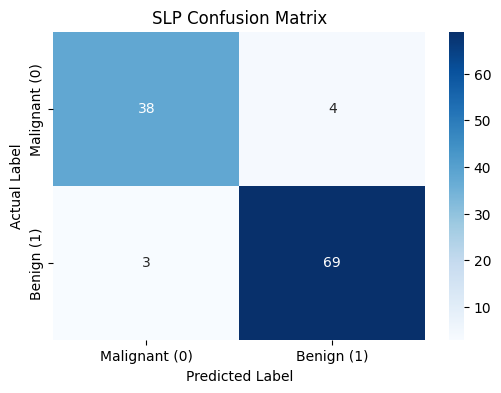

In [15]:
cm = confusion_matrix(y_test, y_pred_slp)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant (0)', 'Benign (1)'],
    yticklabels=['Malignant (0)', 'Benign (1)']
)

plt.title('SLP Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

slp_test_accuracy = slp_acc

### 2.6 - SLP Limitations Markdown

### Limitation of the Single-Layer Perceptron (SLP)

The fundamental limitation of an SLP is that it can learn only linearly separable decision boundaries.

- One decision boundary: The SLP uses a single neuron to create one hyperplane that separates the two classes in the 30-dimensional feature space.

- Limited learning ability: It cannot learn complex, nonlinear relationships between features because it has no hidden layers.

- Breast cancer classification: The relationship between tumor features and cancer diagnosis may be complex, so a single hyperplane may not classify every sample correctly. The classes are not guaranteed to be perfectly linearly separable.

Conclusion: The SLP provides a useful baseline for evaluating breast cancer classification performance. However, its limited decision boundary may restrict its predictive ability.

This motivates Task 3: Multi-Layer Perceptron (MLP), which introduces hidden layers and nonlinear activation functions to learn more complex patterns and potentially improve classification performance.


## Task 3: Multi-Layer Perceptron (MLP) - Activation Functions

### 3.1 - Build the MLP ( ReLU )

In [16]:
model_mlp = keras.Sequential([
    keras.layers.Dense(64 , activation = 'relu', input_shape = (30,)),
    keras.layers.Dense(32 , activation = 'relu'),
    keras.layers.Dense(1 , activation = 'sigmoid')
])

model_mlp.summary()

c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
layer1 = 30 * 64 + 64

layer2 = 64 * 32 + 32

layer3 = 32 * 1 + 1

total_params = layer1 + layer2 + layer3

print("Layer 1 parameters:", layer1)
print("Layer 2 parameters:", layer2)
print("Output layer parameters:", layer3)
print("Total parameters:", total_params)

Layer 1 parameters: 1984
Layer 2 parameters: 2080
Output layer parameters: 33
Total parameters: 4097


### 3.2 - WHY hidden layers - Markdown



### Understanding Hidden Layers and Non-Linear Transformations

Each Dense layer learns a transformation of its input features using trainable weights and biases. The ReLU activation function introduces non-linearity, allowing the network to learn complex patterns that a simple linear model cannot capture.

- First hidden layer (64 neurons): Learns initial combinations and patterns from the 30 input features.

- Second hidden layer (32 neurons): Combines the learned patterns from the first layer to discover more complex feature interactions.

- Output layer (1 neuron): Uses the sigmoid activation function to predict the probability of the sample belonging to class 1 (benign).

Why use two hidden layers?

The Universal Approximation Theorem states that a neural network with a single hidden layer and a suitable activation function can approximate a broad class of continuous functions, given sufficient neurons and appropriate conditions.

However, using two hidden layers allows the network to compose multiple levels of feature transformations. This can represent some complex functions more efficiently and may improve learning in practice, although it does not guarantee faster convergence or better performance on every dataset.

Deeper networks can build increasingly complex feature hierarchies, but adding more layers also increases computational cost and may make training more challenging.

For this breast cancer dataset, the two-hidden-layer MLP provides a reasonable balance between learning capacity and model complexity.

### 3.3 - Compile and Train MLP ( ReLU )

In [18]:
model_mlp.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [19]:
history_mlp = model_mlp.fit(X_train_sc,y_train,epochs=100,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8435 - loss: 0.4714 - val_accuracy: 0.8696 - val_loss: 0.3727
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9291 - loss: 0.2712 - val_accuracy: 0.9130 - val_loss: 0.2706
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9462 - loss: 0.1838 - val_accuracy: 0.9130 - val_loss: 0.2169
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9535 - loss: 0.1389 - val_accuracy: 0.9348 - val_loss: 0.1811
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9682 - loss: 0.1109 - val_accuracy: 0.9348 - val_loss: 0.1526
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9707 - loss: 0.0928 - val_accuracy: 0.9565 - val_loss: 0.1279
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9829 - loss: 0.0803 - val_accuracy: 0.9565 - val_loss: 0.1098
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9853 - loss: 0.0704 - val_accuracy: 0.9565 

### 3.4 - Compare activation functions

#### (A) activation = 'tanh'

In [20]:
model_tanh = keras.Sequential([
    keras.layers.Dense(64, activation='tanh', input_shape=(30,)),
    keras.layers.Dense(32, activation='tanh'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_tanh.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history_tanh = model_tanh.fit(X_train_sc, y_train,epochs=100,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7139 - loss: 0.5303 - val_accuracy: 0.8913 - val_loss: 0.3181
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9413 - loss: 0.1829 - val_accuracy: 0.9130 - val_loss: 0.2284
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9584 - loss: 0.1252 - val_accuracy: 0.9130 - val_loss: 0.1676
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9731 - loss: 0.0976 - val_accuracy: 0.9348 - val_loss: 0.1271
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9780 - loss: 0.0839 - val_accuracy: 0.9783 - val_loss: 0.0987
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9829 - loss: 0.0749 - val_accuracy: 0.9783 - val_loss: 0.0813
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9829 - loss: 0.0686 - val_accuracy: 0.9783 - val_loss: 0.0731
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9853 - loss: 0.0638 - val_accuracy: 0.9783 

#### (B) activation = 'sigmoid'

In [21]:
model_sigmoid = keras.Sequential([
    keras.layers.Dense(64, activation='sigmoid', input_shape=(30,)),
    keras.layers.Dense(32, activation='sigmoid'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_sigmoid.compile(optimizer='adam', loss='binary_crossentropy',metrics=['accuracy'])

history_sigmoid = model_sigmoid.fit(X_train_sc, y_train,epochs=100,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.6406 - loss: 0.6389 - val_accuracy: 0.5000 - val_loss: 0.6855
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6577 - loss: 0.5759 - val_accuracy: 0.5435 - val_loss: 0.6130
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7482 - loss: 0.5104 - val_accuracy: 0.7391 - val_loss: 0.5571
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8533 - loss: 0.4440 - val_accuracy: 0.8696 - val_loss: 0.4840
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8998 - loss: 0.3773 - val_accuracy: 0.8261 - val_loss: 0.4209
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9267 - loss: 0.3163 - val_accuracy: 0.8696 - val_loss: 0.3636
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9413 - loss: 0.2678 - val_accuracy: 0.8696 - val_loss: 0.3169
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9462 - loss: 0.2276 - val_accuracy: 0.8913

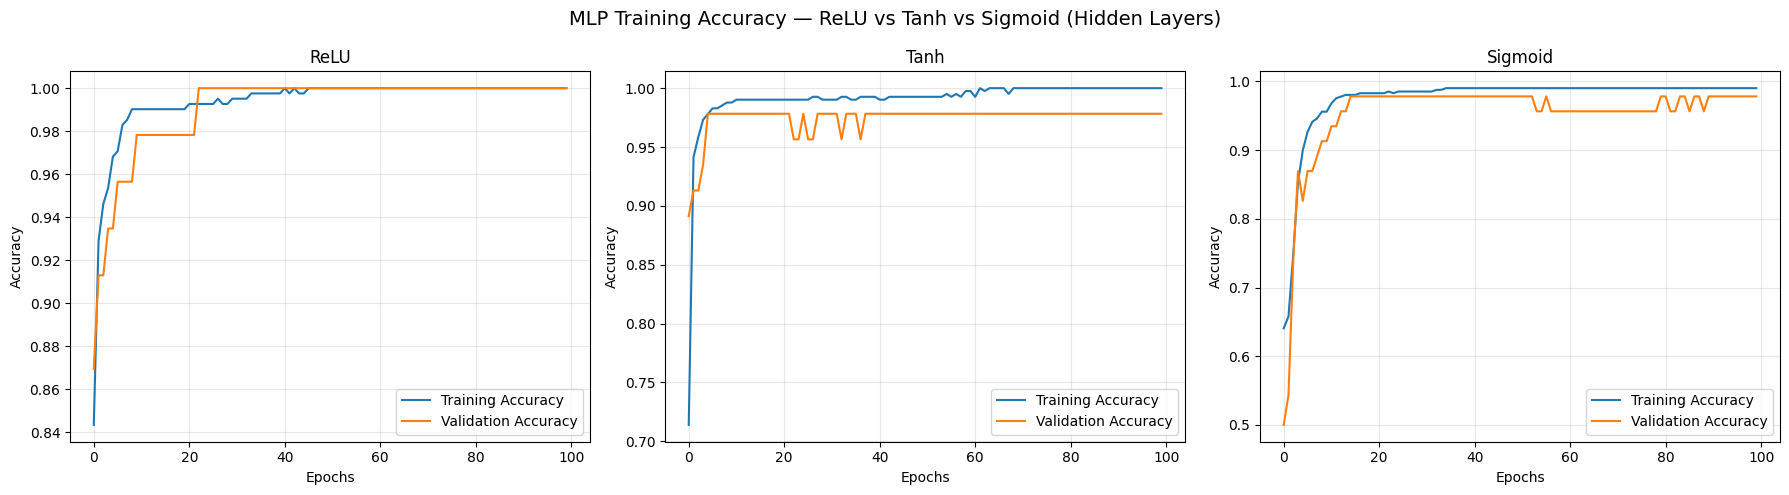

In [22]:
histories = [history_mlp, history_tanh, history_sigmoid]
names = ['ReLU', 'Tanh', 'Sigmoid']

plt.figure(figsize=(18, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)

    plt.plot(histories[i].history['accuracy'], label='Training Accuracy')
    plt.plot(histories[i].history['val_accuracy'], label='Validation Accuracy')

    plt.title(names[i])
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.suptitle(
    'MLP Training Accuracy — ReLU vs Tanh vs Sigmoid (Hidden Layers)',
    fontsize=14
)

plt.tight_layout()
plt.show()

### 3.5 - Activation Functions Markdown

### Comparison of Activation Functions in Hidden Layers

We compared ReLU, Tanh, and Sigmoid using the same MLP architecture and training settings. The main differences are how they transform inputs and how efficiently they allow the network to learn.

#### 1. ReLU (Rectified Linear Unit)

- Formula: \(f(x)=\max(0,x)\)
- Output: Zero for negative inputs and the input value for positive inputs.
- Advantages: Avoids vanishing gradients for positive inputs and often converges quickly on tabular datasets.
- Limitation: Negative inputs have zero gradient, which can cause some neurons to stop learning. This is known as the dying ReLU problem.

#### 2. Tanh (Hyperbolic Tangent)

- Output range: \((-1,1)\)
- Advantages: The output is zero-centred, which can help optimization compared with Sigmoid.
- Limitation: Tanh can suffer from vanishing gradients when inputs fall into saturated regions, especially in deep networks.

#### 3. Sigmoid

- Output range: \((0,1)\)
- Advantages: Produces smooth, bounded outputs and is useful in the output layer for binary classification.
- Limitations: It is not zero-centred and can suffer from severe vanishing gradients in hidden layers, making learning slower. ReLU or Tanh is generally preferred for hidden layers in this type of network.

### Which Activation Function Performed Best?

Based on the training and validation accuracy plots:

- ReLU: Reached approximately 100% training and validation accuracy quickly and maintained stable validation performance.

- Tanh: Reached approximately 100% training accuracy, while validation accuracy remained around 98%, with some fluctuations.

- Sigmoid: Reached high accuracy quickly, but its validation accuracy fluctuated slightly near the end of training.

Conclusion: ReLU appears to perform best overall on this dataset because it converges quickly and maintains high, stable validation accuracy. Tanh also performs well, while Sigmoid shows slightly less stable validation performance. ReLU is therefore a good choice for the hidden layers of this MLP.

### 3.6 - Evaluate best MLP

In [23]:
relu_loss, relu_acc = model_mlp.evaluate(X_test_sc, y_test, verbose=0)

print("ReLU MLP Test Accuracy:", round(relu_acc * 100, 2), "%")

y_pred_relu = (model_mlp.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()

ReLU MLP Test Accuracy: 95.61 %


In [24]:
print("\nClassification Report - ReLU MLP:")
print(classification_report(
    y_test,
    y_pred_relu,
    target_names=["Malignant (0)", "Benign (1)"]
))


Classification Report - ReLU MLP:
               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114



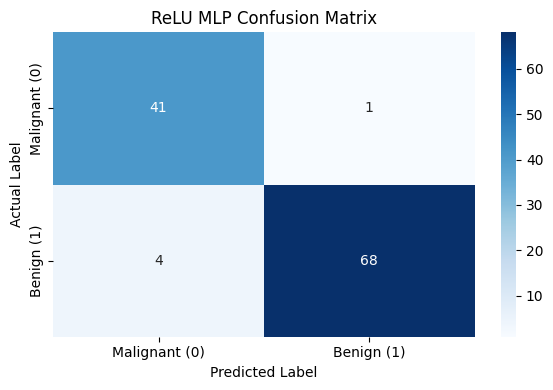

In [25]:
cm_relu = confusion_matrix(y_test, y_pred_relu)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_relu,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant (0)", "Benign (1)"],
    yticklabels=["Malignant (0)", "Benign (1)"]
)
plt.title("ReLU MLP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [26]:
results = pd.DataFrame({
    "Model": ["SLP", "MLP (ReLU)"],
    "Test Accuracy (%)": [
        round(slp_test_accuracy * 100, 2),
        round(relu_acc * 100, 2)
    ]
})

print("\nTest Accuracy Comparison:")
print(results.to_string(index=False))


difference = (relu_acc - slp_test_accuracy) * 100
print(f"\nReLU MLP accuracy improvement over SLP: {difference:+.2f} percentage points")


Test Accuracy Comparison:
     Model  Test Accuracy (%)
       SLP              93.86
MLP (ReLU)              95.61

ReLU MLP accuracy improvement over SLP: +1.75 percentage points


### Task 4: Early Stopping

### 4.1 - Build MLP for Early Stopping Experiment

In [27]:
model_overfit = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_overfit.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

model_overfit.summary()

history_overfit = model_overfit.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,verbose=1)

c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8020 - loss: 0.4558 - val_accuracy: 0.9130 - val_loss: 0.3005
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9560 - loss: 0.1737 - val_accuracy: 0.9348 - val_loss: 0.1886
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9633 - loss: 0.1092 - val_accuracy: 0.9565 - val_loss: 0.1420
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9756 - loss: 0.0842 - val_accuracy: 0.9783 - val_loss: 0.1060
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9804 - loss: 0.0711 - val_accuracy: 0.9783 - val_loss: 0.0826
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9853 - loss: 0.0618 - val_accuracy: 0.9783 - val_loss: 0.0708
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9853 - loss: 0.0555 - val_accuracy: 0.9783 - val_loss: 0.0686
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9878 - loss: 0.0492 - val_accuracy: 0.9783 -

### 4.2 - Add Early Stopping Callback

In [28]:
model_es = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_es.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

es = EarlyStopping(monitor='val_loss',patience=15,restore_best_weights=True,verbose=1)

history_es = model_es.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,callbacks=[es],verbose=1)


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8851 - loss: 0.3990 - val_accuracy: 0.9130 - val_loss: 0.2802
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9560 - loss: 0.1646 - val_accuracy: 0.9348 - val_loss: 0.1858
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9707 - loss: 0.1070 - val_accuracy: 0.9565 - val_loss: 0.1325
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9804 - loss: 0.0829 - val_accuracy: 0.9783 - val_loss: 0.0977
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9829 - loss: 0.0696 - val_accuracy: 0.9783 - val_loss: 0.0777
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9829 - loss: 0.0611 - val_accuracy: 0.9783 - val_loss: 0.0689
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9829 - loss: 0.0542 - val_accuracy: 0.9783 - val_loss: 0.0589
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9853 - loss: 0.0495 - val_accuracy: 0.9

### 4.3 - WHY Early Stopping - Markdown

### Understanding the EarlyStopping Parameters

Early Stopping helps prevent overfitting by monitoring validation performance and stopping training when the model stops improving.

We used the following four parameters:

* 1. monitor = 'val_loss'

Monitors the validation loss after each epoch rather than the training loss. Training loss can continue to decrease even when the model begins to overfit. Validation loss helps indicate how well the model generalizes to unseen data.

* 2. patience = 15

Allows 15 consecutive epochs without an improvement in validation loss before stopping training. This prevents training from stopping too early because of a temporary plateau or small fluctuations in validation performance.

* 3. restore_best_weights = True

Restores the model weights from the epoch with the lowest validation loss after training stops. Without this setting, the model would retain the weights from the final epoch, which may perform worse if overfitting occurred after the best epoch.

* 4. verbose=1

Displays a message indicating when training stops and, when applicable, that the best weights have been restored. This makes it easier to see when Early Stopping is triggered.

### Conclusion

Early Stopping allows us to set a large maximum number of epochs, such as 300, while stopping training when validation loss no longer improves. By restoring the best weights, it helps retain the model state with the strongest validation performance and can reduce overfitting.

### 4.4 - Plot Early Stopping Curves

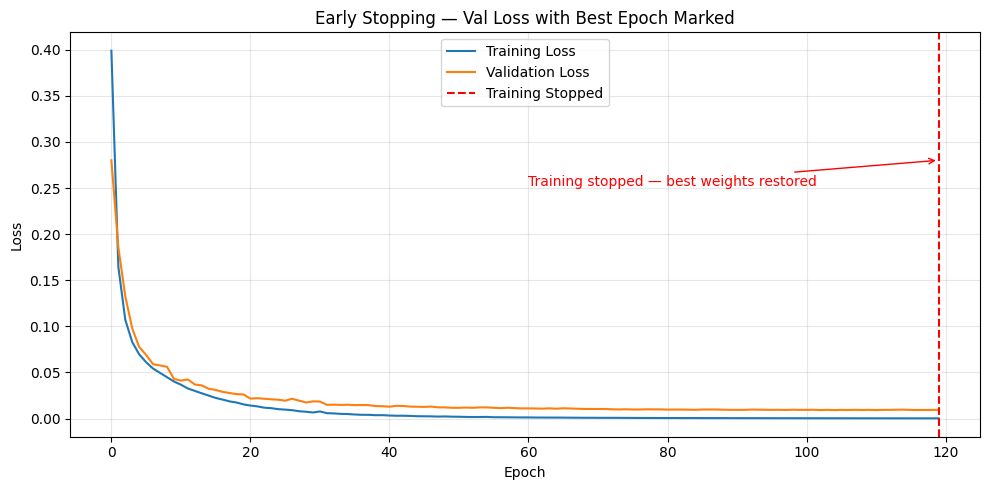

In [29]:
train_loss = history_es.history['loss']
val_loss = history_es.history['val_loss']

stop_epoch = len(train_loss)

plt.figure(figsize=(10, 5))

plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')

plt.axvline(x=stop_epoch - 1, color='red', linestyle='--',label='Training Stopped')

plt.annotate(
    'Training stopped — best weights restored',
    xy=(stop_epoch - 1, max(val_loss)),
    xytext=(stop_epoch * 0.5, max(val_loss) * 0.9),
    color='red',
    arrowprops=dict(arrowstyle='->', color='red')
)

plt.title('Early Stopping — Val Loss with Best Epoch Marked')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 4.5 - Compare: with vs without Early Stopping

In [30]:
model_no_es = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_no_es.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history_no_es = model_no_es.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8484 - loss: 0.4774 - val_accuracy: 0.9130 - val_loss: 0.3307
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9609 - loss: 0.2054 - val_accuracy: 0.9130 - val_loss: 0.1973
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9682 - loss: 0.1166 - val_accuracy: 0.9565 - val_loss: 0.1431
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9804 - loss: 0.0833 - val_accuracy: 0.9565 - val_loss: 0.1100
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9829 - loss: 0.0667 - val_accuracy: 0.9783 - val_loss: 0.0830
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9878 - loss: 0.0566 - val_accuracy: 0.9783 - val_loss: 0.0723
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9878 - loss: 0.0502 - val_accuracy: 0.9783 - val_loss: 0.0659
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9902 - loss: 0.0463 - val_accuracy: 0.9

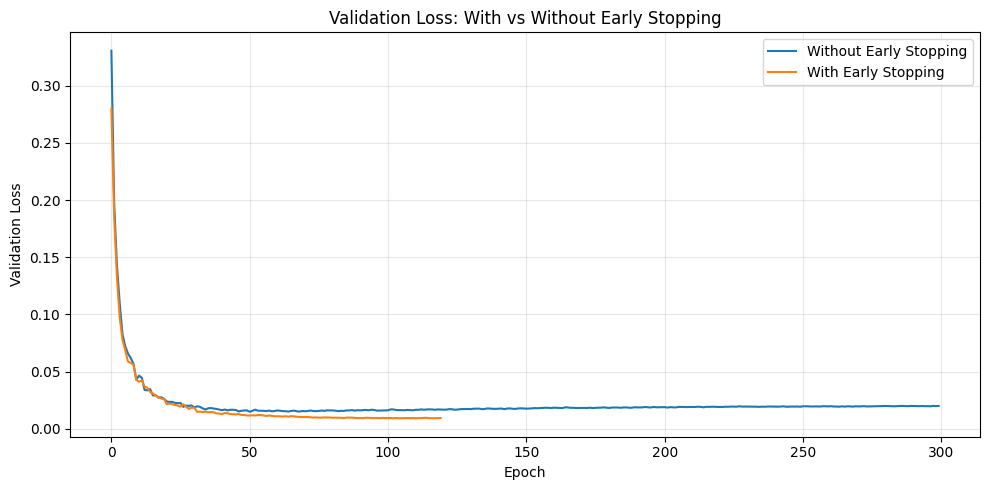

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(history_no_es.history['val_loss'],label='Without Early Stopping')

plt.plot(history_es.history['val_loss'],label='With Early Stopping')

plt.title('Validation Loss: With vs Without Early Stopping')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [32]:
loss_no_es, acc_no_es = model_no_es.evaluate(X_test_sc, y_test, verbose=0)

loss_es, acc_es = model_es.evaluate(X_test_sc, y_test, verbose=0)

print("Test Results")
print("-" * 40)
print(f"Without Early Stopping: {acc_no_es * 100:.2f}%")
print(f"With Early Stopping:    {acc_es * 100:.2f}%")

print("\nFinal recorded validation losses:")
print(f"Without Early Stopping: {history_no_es.history['val_loss'][-1]:.4f}")
print(f"With Early Stopping:    {history_es.history['val_loss'][-1]:.4f}")

best_epoch_no_es = (
    history_no_es.history['val_loss'].index(
        min(history_no_es.history['val_loss'])
    ) + 1
)

best_epoch_es = (
    history_es.history['val_loss'].index(
        min(history_es.history['val_loss'])
    ) + 1
)

print(f"\nBest validation-loss epoch without Early Stopping: {best_epoch_no_es}")
print(f"Best validation-loss epoch with Early Stopping:    {best_epoch_es}")


Test Results
----------------------------------------
Without Early Stopping: 94.74%
With Early Stopping:    95.61%

Final recorded validation losses:
Without Early Stopping: 0.0200
With Early Stopping:    0.0095

Best validation-loss epoch without Early Stopping: 51
Best validation-loss epoch with Early Stopping:    105


## Task 5: Dropout Layers

### 5.1 - Build MLP with Dropout

In [33]:
model_drop = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid')
])

model_drop.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

### 5.2 WHY Dropout - Markdown

### How Dropout Reduces Overfitting

1. Randomly dropping neurons

Dropout(rate=0.3) randomly sets 30% of neuron activations to zero during each training batch. This prevents the network from relying too heavily on particular neurons.

2. Learning redundant representations

Dropout encourages the network to learn redundant representations by distributing useful information across multiple neurons. As a result, the model becomes less dependent on any single neuron and can generalize better to unseen data.

3. Behavior during inference

During inference, such as when using model.predict(), Dropout is automatically disabled. All neurons contribute to the prediction. Keras uses inverted dropout: during training, the remaining activations are scaled by the keep probability, \(1 - 0.3 = 0.7\), so no additional scaling is needed during inference.

Conclusion: Dropout is a regularization technique that can reduce overfitting, reduce reliance on individual neurons, and improve generalization. However, its effectiveness depends on the dataset, model architecture, and dropout rate.

### 5.3 - Train with Dropout + Early Stopping

In [34]:
model_drop.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

es_drop = EarlyStopping(monitor='val_loss',patience=20,restore_best_weights=True,verbose=1)

history_drop = model_drop.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,callbacks=[es_drop],verbose=1)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8240 - loss: 0.4334 - val_accuracy: 0.9130 - val_loss: 0.2997
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9511 - loss: 0.1957 - val_accuracy: 0.9130 - val_loss: 0.2100
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9633 - loss: 0.1261 - val_accuracy: 0.9130 - val_loss: 0.1647
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9682 - loss: 0.1117 - val_accuracy: 0.9565 - val_loss: 0.1294
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9756 - loss: 0.0796 - val_accuracy: 0.9565 - val_loss: 0.1054
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9829 - loss: 0.0731 - val_accuracy: 0.9565 - val_loss: 0.0936
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9878 - loss: 0.0665 - val_accuracy: 0.9565 - val_loss: 0.0839
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9829 - loss: 0.0585 - val_accuracy: 0.9565

### 5.4 - Effect of Dropout rate

#### Model with Dropout Rate 0.1

In [35]:
es_compare = keras.callbacks.EarlyStopping(monitor='val_loss',patience=20,restore_best_weights=True,verbose=1)

model_drop_01 = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(1, activation='sigmoid')
])

model_drop_01.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history_drop_01 = model_drop_01.fit(
    X_train_sc, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_compare],
    verbose=1
)

Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.7946 - loss: 0.4846 - val_accuracy: 0.9348 - val_loss: 0.2917
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9413 - loss: 0.2087 - val_accuracy: 0.9565 - val_loss: 0.1832
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9609 - loss: 0.1241 - val_accuracy: 0.9565 - val_loss: 0.1431
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9756 - loss: 0.0889 - val_accuracy: 0.9783 - val_loss: 0.1068
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9780 - loss: 0.0768 - val_accuracy: 0.9783 - val_loss: 0.0885
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9804 - loss: 0.0637 - val_accuracy: 0.9783 - val_loss: 0.0728
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9853 - loss: 0.0555 - val_accuracy: 0.9783 - val_loss: 0.0672
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9853 - loss: 0.0528 - val_accuracy: 0.97

#### Model with Dropout Rate 0.5 

In [36]:
model_drop_05 = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation='sigmoid')
])

model_drop_05.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history_drop_05 = model_drop_05.fit(
    X_train_sc, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_compare],
    verbose=1
)

Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7408 - loss: 0.5480 - val_accuracy: 0.9565 - val_loss: 0.3220
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9169 - loss: 0.2798 - val_accuracy: 0.9130 - val_loss: 0.2152
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9413 - loss: 0.1934 - val_accuracy: 0.9348 - val_loss: 0.1690
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9584 - loss: 0.1434 - val_accuracy: 0.9565 - val_loss: 0.1434
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9633 - loss: 0.1242 - val_accuracy: 0.9783 - val_loss: 0.1161
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9682 - loss: 0.1122 - val_accuracy: 0.9783 - val_loss: 0.1005
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9756 - loss: 0.0994 - val_accuracy: 0.9783 - val_loss: 0.0901
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9658 - loss: 0.1085 - val_accuracy: 0.97

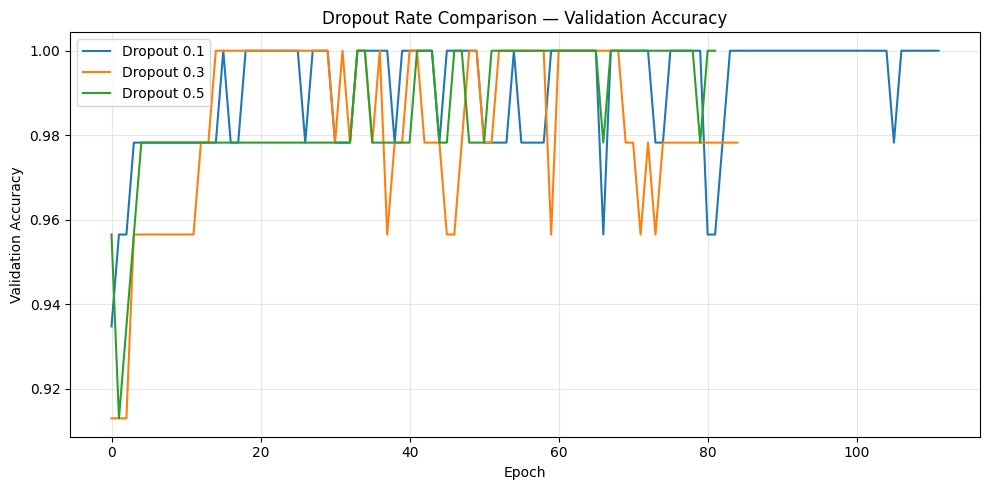

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(history_drop_01.history['val_accuracy'],label='Dropout 0.1')

plt.plot(history_drop.history['val_accuracy'],label='Dropout 0.3')

plt.plot(history_drop_05.history['val_accuracy'],label='Dropout 0.5')

plt.title('Dropout Rate Comparison — Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Comparing Dropout Rates

Dropout rate controls the proportion of neuron activations randomly set to zero during training. Choosing an appropriate rate balances overfitting and underfitting.

- Dropout = 0.1 (10%): A low dropout rate provides relatively little regularisation. The model may rely too heavily on specific neurons and remain more prone to overfitting.

- Dropout = 0.3 (30%): Provides a moderate level of regularisation. It can help reduce overfitting while allowing enough activations to remain for effective learning.

- Dropout = 0.5 (50%): A high dropout rate removes many activations during each training batch. This can make learning harder, slow convergence, and cause underfitting if the model cannot learn the underlying patterns effectively.

### Conclusion

The validation accuracy curves help show how the dropout rate affects generalisation. A rate that is too low may not sufficiently control overfitting, while a rate that is too high may restrict learning. The best rate is the one that provides strong, stable validation performance without excessive overfitting or underfitting.

In [38]:
drop_loss, drop_acc = model_drop.evaluate(X_test_sc, y_test, verbose=0)

print("Dropout (0.3) Test Accuracy:", round(drop_acc * 100, 2), "%")

results.loc[len(results)] = [
    "MLP (Dropout 0.3)",
    round(drop_acc * 100, 2)
]

print("\nUpdated Results Table:")
print(results.to_string(index=False))


Dropout (0.3) Test Accuracy: 95.61 %

Updated Results Table:
            Model  Test Accuracy (%)
              SLP              93.86
       MLP (ReLU)              95.61
MLP (Dropout 0.3)              95.61


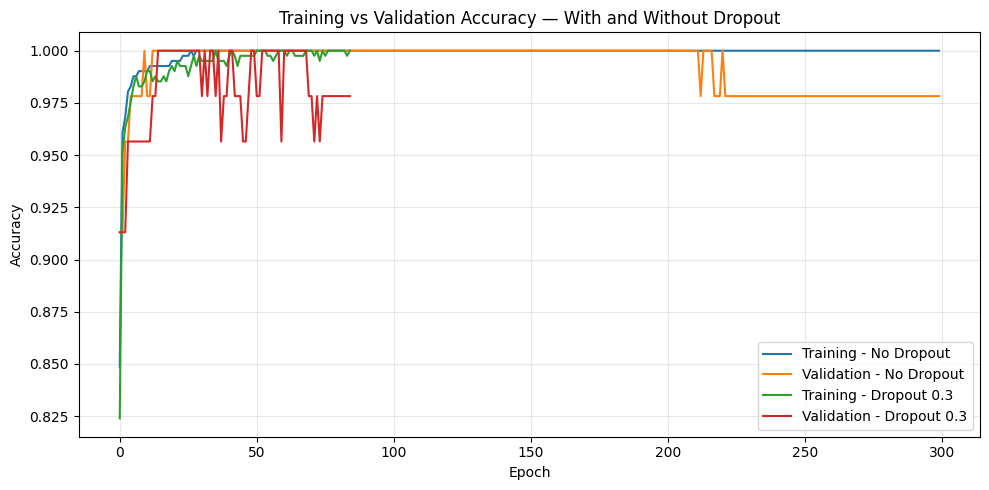

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(history_no_es.history['accuracy'],label='Training - No Dropout')
plt.plot(history_no_es.history['val_accuracy'],label='Validation - No Dropout')

plt.plot(history_drop.history['accuracy'],label='Training - Dropout 0.3')
plt.plot(history_drop.history['val_accuracy'],label='Validation - Dropout 0.3')

plt.title('Training vs Validation Accuracy — With and Without Dropout')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Task 6: Regularization (L1, L2, L1-L2)

### 6.1 - Build MLP with L2 Regularization

In [41]:
model_l2 = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=regularizers.l2(0.001)
    ),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),
    keras.layers.Dense(1, activation='sigmoid')
])

model_l2.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

es_l2 = EarlyStopping(monitor='val_loss',patience=20,restore_best_weights=True,verbose=1)

history_l2 = model_l2.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,callbacks=[es_l2],verbose=1)

c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8655 - loss: 0.5295 - val_accuracy: 0.8913 - val_loss: 0.4089
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9633 - loss: 0.2946 - val_accuracy: 0.9130 - val_loss: 0.3104
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9707 - loss: 0.2329 - val_accuracy: 0.9348 - val_loss: 0.2637
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9829 - loss: 0.2044 - val_accuracy: 0.9565 - val_loss: 0.2339
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9829 - loss: 0.1913 - val_accuracy: 0.9783 - val_loss: 0.2112
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9829 - loss: 0.1807 - val_accuracy: 0.9565 - val_loss: 0.2021
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9878 - loss: 0.1714 - val_accuracy: 0.9783 - val_loss: 0.1933
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9902 - loss: 0.1638 - val_accuracy: 0.

### 6.2 - WHY Regularization - Markdown

### Understanding L2 Regularization

L2 regularization is a technique used to reduce overfitting by penalizing large weight values in a neural network.

1. Effect on model weights

The penalty encourages weights to become smaller, pushing them toward zero without generally forcing them to become exactly zero. This discourages the model from relying too heavily on a few large weights.

2. How L2 regularization reduces overfitting

By discouraging large weights, L2 regularization can produce a smoother decision boundary. The model may distribute its predictions across many smaller weights rather than relying heavily on a few dominant ones. This can reduce model variance and improve generalization to unseen data.

3. Choosing the regularization strength

In this experiment, we use (lambda = 0.001), which provides a moderate regularization penalty.

- Too small a value: The penalty may be too weak to meaningfully reduce overfitting.

- Too large a value: The weights may be constrained too strongly, preventing the model from learning important patterns and potentially causing underfitting.

Conclusion: L2 regularization helps control model complexity by penalizing large weights. Its effectiveness depends on choosing a suitable regularization strength and evaluating the model's validation and test performance.

### 6.3 - Build MLP with L1 Regularization

In [42]:
model_l1 = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=regularizers.l1(0.001)
    ),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=regularizers.l1(0.001)
    ),
    keras.layers.Dense(1, activation='sigmoid')
])

model_l1.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

es_l1 = EarlyStopping(monitor='val_loss',patience=20,restore_best_weights=True,verbose=1)

history_l1 = model_l1.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,callbacks=[es_l1],verbose=1)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.8606 - loss: 1.5216 - val_accuracy: 0.9565 - val_loss: 1.3442
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9609 - loss: 1.2199 - val_accuracy: 0.9348 - val_loss: 1.2081
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9707 - loss: 1.1130 - val_accuracy: 0.9348 - val_loss: 1.1055
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9756 - loss: 1.0348 - val_accuracy: 0.9565 - val_loss: 1.0246
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9780 - loss: 0.9682 - val_accuracy: 0.9783 - val_loss: 0.9588
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9804 - loss: 0.9065 - val_accuracy: 0.9783 - val_loss: 0.8937
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9853 - loss: 0.8462 - val_accuracy: 0.9783 - val_loss: 0.8363
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9853 - loss: 0.7900 - val_accuracy: 0.9

### 6.4 - Build MLP with L1-L2 (ElasticNet)

In [43]:
model_l1l2 = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=regularizers.l1_l2(l1=0.0001, l2=0.001)
    ),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=regularizers.l1_l2(l1=0.0001, l2=0.001)
    ),
    keras.layers.Dense(1, activation='sigmoid')
])

model_l1l2.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

es_l1l2 = EarlyStopping(monitor='val_loss',patience=20,restore_best_weights=True,verbose=1)

history_l1l2 = model_l1l2.fit(X_train_sc,y_train,epochs=300,batch_size=32,validation_split=0.1,callbacks=[es_l1l2],verbose=1)


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.8557 - loss: 0.7190 - val_accuracy: 0.9130 - val_loss: 0.5821
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9462 - loss: 0.4300 - val_accuracy: 0.8913 - val_loss: 0.4380
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9682 - loss: 0.3469 - val_accuracy: 0.9565 - val_loss: 0.3656
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9780 - loss: 0.3127 - val_accuracy: 0.9783 - val_loss: 0.3299
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9829 - loss: 0.2919 - val_accuracy: 0.9783 - val_loss: 0.3071
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9829 - loss: 0.2769 - val_accuracy: 0.9783 - val_loss: 0.2932
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9853 - loss: 0.2631 - val_accuracy: 0.9783 - val_loss: 0.2782
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9878 - loss: 0.2519 - val_accuracy: 0.

### 6.5 - Regularization Comparison Plot

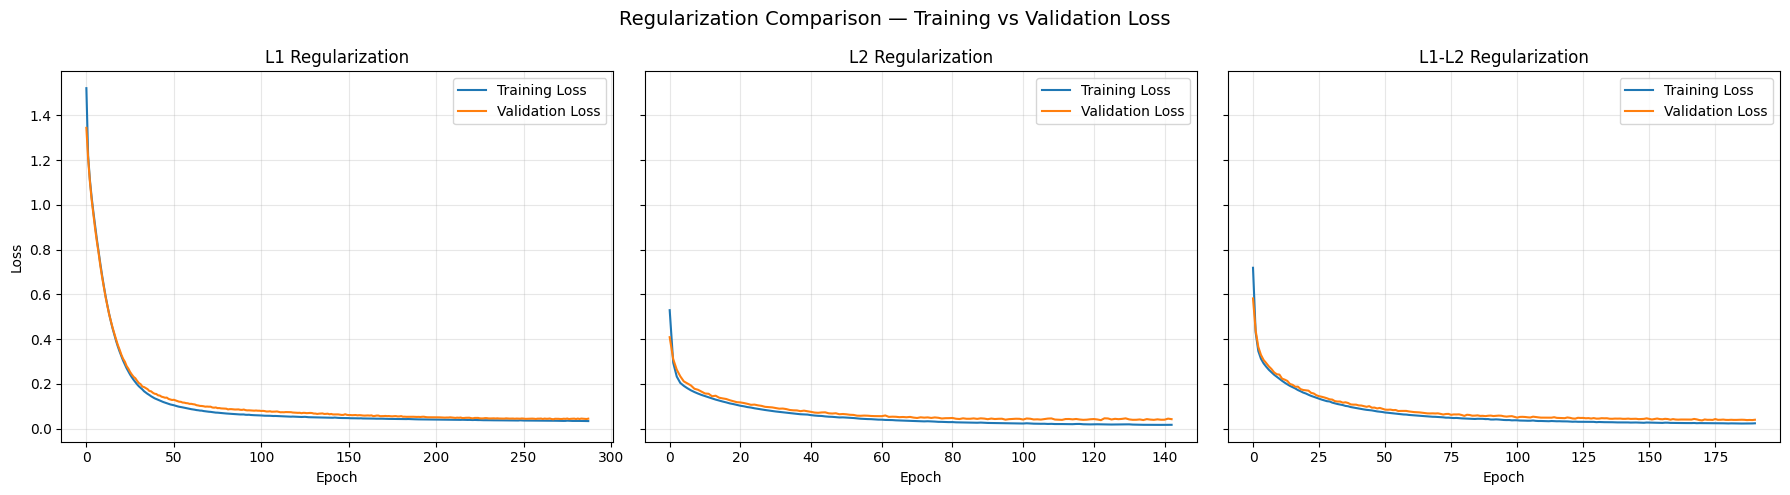

In [44]:
histories = [
    ("L1 Regularization", history_l1),
    ("L2 Regularization", history_l2),
    ("L1-L2 Regularization", history_l1l2)
]

all_losses = []
for _, history in histories:
    all_losses.extend(history.history["loss"])
    all_losses.extend(history.history["val_loss"])

y_min = min(all_losses)
y_max = max(all_losses)
padding = (y_max - y_min) * 0.05

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (name, history) in zip(axes, histories):
    ax.plot(history.history["loss"], label="Training Loss")
    ax.plot(history.history["val_loss"], label="Validation Loss")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Loss")

fig.suptitle(
    "Regularization Comparison — Training vs Validation Loss",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [ ]:
histories = {
    "L1": history_l1,
    "L2": history_l2,
    "L1-L2 (ElasticNet)": history_l1l2
}

for name, h in histories.items():
    gaps = [abs(a - b) for a, b in zip(h.history["loss"], h.history["val_loss"])]
    best_val_acc = max(h.history["val_accuracy"]) * 100

    print(f"{name}:")
    print(f"  Smallest loss gap: {min(gaps):.4f}")
    print(f"  Best validation accuracy: {best_val_acc:.2f}%")


L1:
  Smallest loss gap: 0.0012
  Best validation accuracy: 100.00%
L2:
  Smallest loss gap: 0.0094
  Best validation accuracy: 100.00%
L1-L2 (ElasticNet):
  Smallest loss gap: 0.0077
  Best validation accuracy: 100.00%


### 6.6 - Evaluate all three regularized models

In [47]:
_, acc_mlp = model_mlp.evaluate(X_test_sc, y_test, verbose=0)
_, acc_l1 = model_l1.evaluate(X_test_sc, y_test, verbose=0)
_, acc_l2 = model_l2.evaluate(X_test_sc, y_test, verbose=0)
_, acc_l1l2 = model_l1l2.evaluate(X_test_sc, y_test, verbose=0)

results = pd.DataFrame({
    "Model": ["No Regularization (Best MLP)", "L1", "L2", "L1-L2 (ElasticNet)"],
    "Test Accuracy (%)": [
        round(acc_mlp * 100, 2),
        round(acc_l1 * 100, 2),
        round(acc_l2 * 100, 2),
        round(acc_l1l2 * 100, 2)
    ]
})

results

,Model,Test Accuracy (%)
0,No Regularization (Best MLP),95.61
1,L1,95.61
2,L2,95.61
3,L1-L2 (ElasticNet),95.61


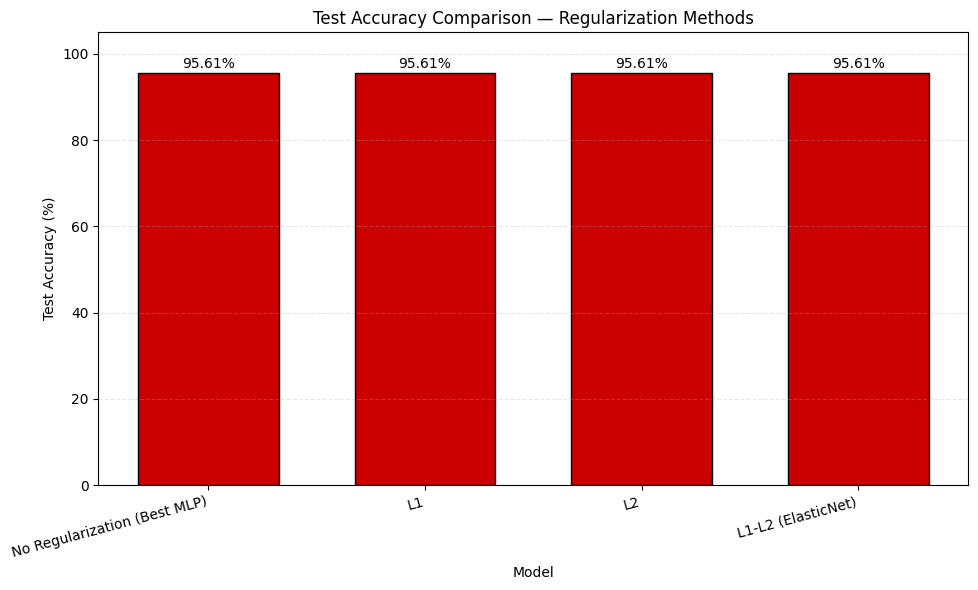

In [48]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    results["Model"],
    results["Test Accuracy (%)"],
    color="#CC0000",
    edgecolor="black",
    width=0.65
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("Test Accuracy Comparison — Regularization Methods")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 105)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## Task 7: Final Comparison

### 7.1 - Best model: combine Dropout + L2 + Early Stopping

In [49]:
final_model = keras.Sequential([
    keras.layers.Dense(
        128, activation="relu",
        kernel_regularizer=regularizers.l2(0.001),
        input_shape=(30,)
    ),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation="sigmoid")
])


final_model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

early_stop = EarlyStopping(monitor="val_loss",patience=20,restore_best_weights=True,verbose=1)

history_final = final_model.fit(X_train_sc, y_train,epochs=300,batch_size=32
                ,validation_split=0.1,callbacks=[early_stop],verbose=1)


Epoch 1/300


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.8093 - loss: 0.6158 - val_accuracy: 0.9348 - val_loss: 0.4199
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9511 - loss: 0.3594 - val_accuracy: 0.9130 - val_loss: 0.3258
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9535 - loss: 0.2714 - val_accuracy: 0.9565 - val_loss: 0.2807
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9707 - loss: 0.2315 - val_accuracy: 0.9565 - val_loss: 0.2518
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9804 - loss: 0.2202 - val_accuracy: 0.9565 - val_loss: 0.2257
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9878 - loss: 0.1965 - val_accuracy: 0.9565 - val_loss: 0.2064
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9829 - loss: 0.1979 - val_accuracy: 0.9565 - val_loss: 0.1993
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9829 - loss: 0.1845 - val_accuracy: 0.9565 - val_l

### 7.2 - Full results comparison table

In [53]:
models = [
    {
        "Model": "SLP (Task 2)",
        "model": model_slp,
        "Architecture": "Dense(1, sigmoid)",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "No"
    },
    {
        "Model": "MLP-ReLU (Task 3)",
        "model": model_mlp,
        "Architecture": "Dense(64) → Dense(32) → Dense(1)",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "No"
    },
    {
        "Model": "MLP + Early Stopping (Task 4)",
        "model": model_es,
        "Architecture": "Dense(128) → Dense(64) → Dense(1)",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "Yes"
    },
    {
        "Model": "MLP + Dropout-best (Task 5)",
        "model": model_drop,
        "Architecture": "Dense(128) → Dense(64) → Dense(1)",
        "Regularization": "None",
        "Dropout Rate": 0.3,
        "Early Stopping": "Yes"
    },
    {
        "Model": "MLP + L2 (Task 6)",
        "model": model_l2,
        "Architecture": "Dense(128) → Dense(64) → Dense(1)",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": 0.0,
        "Early Stopping": "Yes"
    },
    {
        "Model": "Final Combined Model (Task 7.1)",
        "model": final_model,
        "Architecture": "Dense(128) → Dropout → Dense(64) → Dropout → Dense(1)",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": 0.3,
        "Early Stopping": "Yes"
    }
]

rows = []

for item in models:
    y_prob = item["model"].predict(X_test_sc, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    rows.append({
        "Model": item["Model"],
        "Architecture": item["Architecture"],
        "Regularization": item["Regularization"],
        "Dropout Rate": item["Dropout Rate"],
        "Early Stopping": item["Early Stopping"],
        "Test Accuracy": item["model"].evaluate(
            X_test_sc, y_test, verbose=0
        )[1],
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

df = pd.DataFrame(rows)

metric_cols = [
    "Test Accuracy", "Test Precision",
    "Test Recall", "Test F1-Score"
]
df[metric_cols] = (df[metric_cols] * 100).round(2)

df

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP (Task 2),"Dense(1, sigmoid)",None,0.0,No,93.86,94.52,95.83,95.17
1,MLP-ReLU (Task 3),Dense(64) → Dense(32) → Dense(1),None,0.0,No,95.61,98.55,94.44,96.45
2,MLP + Early Stopping (Task 4),Dense(128) → Dense(64) → Dense(1),None,0.0,Yes,95.61,98.55,94.44,96.45
3,MLP + Dropout-best (Task 5),Dense(128) → Dense(64) → Dense(1),None,0.3,Yes,95.61,98.55,94.44,96.45
4,MLP + L2 (Task 6),Dense(128) → Dense(64) → Dense(1),L2 (0.001),0.0,Yes,95.61,98.55,94.44,96.45
5,Final Combined Model (Task 7.1),Dense(128) → Dropout → Dense(64) → Dropout → D...,L2 (0.001),0.3,Yes,95.61,98.55,94.44,96.45
